In [1]:
import json
from html import escape
from urllib.request import Request, urlopen

from IPython.display import HTML, display

# BHI publishes its downloadable-data catalogue through the Data.NSW CKAN API.
# The catalogue is queryable by API; the healthcare observations are supplied as files.
BHI_CATALOGUE_API = (
    "https://data.nsw.gov.au/data/api/3/action/package_show"
    "?id=downloadable-data"
)

request = Request(
    BHI_CATALOGUE_API,
    headers={"User-Agent": "Mozilla/5.0", "Accept": "application/json"},
)
with urlopen(request, timeout=30) as response:
    catalogue_response = json.load(response)

if not catalogue_response.get("success"):
    raise RuntimeError("The Data.NSW catalogue API did not return a successful response.")

bhi_catalogue = catalogue_response["result"]
bhi_resources = sorted(bhi_catalogue["resources"], key=lambda resource: resource["position"])

resource_rows_html = "".join(
    "<tr>"
    f"<td>{escape(resource.get('name') or '')}</td>"
    f"<td>{escape(resource.get('description') or '')}</td>"
    f"<td>{escape(resource.get('format') or '')}</td>"
    f"<td>{'Yes' if resource.get('datastore_active') else 'No'}</td>"
    f"<td><a href='{escape(resource.get('url') or '')}' target='_blank'>Open resource</a></td>"
    "</tr>"
    for resource in bhi_resources
)

display(HTML(
    f"<h3>{escape(bhi_catalogue['title'])}</h3>"
    f"<p>{len(bhi_resources)} resources returned by the Data.NSW catalogue API. "
    "A value of <strong>No</strong> under API datastore means the observations must "
    "be read from the linked file.</p>"
    "<table><thead><tr><th>Resource</th><th>Coverage</th><th>Format</th>"
    "<th>API datastore</th><th>Source</th>"
    f"</tr></thead><tbody>{resource_rows_html}</tbody></table>"
))

Resource,Coverage,Format,API datastore,Source
Healthcare Quarterly - Ambulance,January 2010 to March 2026,excel (xlsx),No,Open resource
Healthcare Quarterly - Emergency Department,January 2010 to March 2026,excel (xlsx),No,Open resource
Healthcare Quarterly - Elective Surgery,January 2010 to March 2026,excel (xlsx),No,Open resource
Healthcare Quarterly - Admitted Patients,January 2010 to March 2026,excel (xlsx),No,Open resource
Adult Admitted Patient Survey,January 2010 to March 2026,excel (xlsx),No,Open resource
BHI - Downloadable Data Landing page,View this page for access to all available downloadable data resources,HTML,No,Open resource


Note, there is no API but you can use html parser or Beautiful Soup to go to the web page and get the href for the downloadable data box-links.

# Exploring Data

After downloading and splitting the excel files apart into separate CSVs, we can begin to explore the data.

In [4]:
import csv
from html import escape
from pathlib import Path

from IPython.display import HTML, display

# Support running the notebook from either the project root or notebooks/.
candidate_data_directories = [
    Path.cwd() / "data" / "2.interim" / "bhi",
    Path.cwd().parent / "data" / "2.interim" / "bhi",
]
bhi_data_directory = next(
    (path for path in candidate_data_directories if path.is_dir()),
    None,
)
if bhi_data_directory is None:
    raise FileNotFoundError("Could not find data/2.interim/bhi.")

ed_overall_files = sorted(bhi_data_directory.glob("*_ED_*__Overall_results.csv"))
if len(ed_overall_files) != 1:
    raise FileNotFoundError(
        f"Expected one ED overall-results file, found {len(ed_overall_files)}."
    )

ed_overall_path = ed_overall_files[0]
with ed_overall_path.open(encoding="utf-8-sig", newline="") as csv_file:
    reader = csv.DictReader(csv_file)
    ed_overall_results = list(reader)
    columns = reader.fieldnames or []

def is_numeric_column(column):
    non_blank_values = [
        row[column].strip() for row in ed_overall_results if row[column].strip()
    ]
    if not non_blank_values:
        return False

    try:
        for value in non_blank_values:
            float(value.replace(",", ""))
    except ValueError:
        return False
    return True

categorical_columns = [
    column for column in columns if not is_numeric_column(column)
]
categorical_unique_values = {
    column: sorted(
        {row[column].strip() for row in ed_overall_results if row[column].strip()}
    )
    for column in categorical_columns
}

# Keep every value in categorical_unique_values; show a short preview in the notebook.
preview_rows = "".join(
    "<tr>"
    f"<td>{escape(column)}</td>"
    f"<td>{len(values)}</td>"
    f"<td>{escape(', '.join(values[:10]))}{' ...' if len(values) > 10 else ''}</td>"
    "</tr>"
    for column, values in categorical_unique_values.items()
)
display(HTML(
    f"<p>Loaded <strong>{len(ed_overall_results):,}</strong> rows from "
    f"<code>{escape(ed_overall_path.name)}</code>.</p>"
    "<table><thead><tr><th>Column</th><th>Unique non-blank values</th>"
    f"<th>Preview</th></tr></thead><tbody>{preview_rows}</tbody></table>"
))

Column,Unique non-blank values,Preview
reporting_category,1,Total
subcategory,0,
reporting_period,66,"Apr-Jun 2010, Apr-Jun 2011, Apr-Jun 2012, Apr-Jun 2013, Apr-Jun 2014, Apr-Jun 2015, Apr-Jun 2016, Apr-Jun 2017, Apr-Jun 2018, Apr-Jun 2019 ..."
reporting_level,4,"Hospital, LHD, NSW, Peergroup"
entity_id,104,"A1, A2, A202, A207, A208, A212, A233, A237, A3, B ..."
entity_longname,104,"Armidale Hospital, Auburn Hospital, Ballina District Hospital, Bankstown-Lidcombe Hospital, Batemans Bay Hospital and Health Service, Bathurst Health Service, Belmont Hospital, Blacktown Hospital, Blue Mountains District ANZAC Memorial Hospital, Bowral and District Hospital ..."
entity_shortname,104,"Armidale, Auburn, Ballina, Bankstown-Lidcombe, Batemans Bay, Bathurst, Belmont, Blacktown, Blue Mountains, Bowral ..."
lhd_shortname,18,"Central Coast, Far West, Hunter New England, Illawarra Shoalhaven, Mid North Coast, Murrumbidgee, NSW, Nepean Blue Mountains, Northern NSW, Northern Sydney ..."
peer_group_shortname,7,"District group 1, District group 2, Major, NSW, Paediatric specialist, Principal referral, Ungrouped acute - tertiary referral"
measure_name,10,"90th percentile time from arrival at ED to leaving, 90th percentile time to transfer care from paramedics to ED staff, Arrivals by ambulance, Attendances, Emergency presentations, Median time from arrival at ED to leaving, Median time to transfer care from paramedics to ED staff, Percentage of patients leaving ED within four hours, Percentage of patients starting treatment on time, Percentage of patients transferred from paramedics to ED staff within 30 minutes"


In [5]:
measure_names = categorical_unique_values["measure_name"]

print(f"Measure names ({len(measure_names)}):")
for measure_name in measure_names:
    print(f"- {measure_name}")

Measure names (10):
- 90th percentile time from arrival at ED to leaving
- 90th percentile time to transfer care from paramedics to ED staff
- Arrivals by ambulance
- Attendances
- Emergency presentations
- Median time from arrival at ED to leaving
- Median time to transfer care from paramedics to ED staff
- Percentage of patients leaving ED within four hours
- Percentage of patients starting treatment on time
- Percentage of patients transferred from paramedics to ED staff within 30 minutes


In [10]:
lhds = categorical_unique_values["lhd_shortname"]

for lhd in lhds:
    print(lhd)

Central Coast
Far West
Hunter New England
Illawarra Shoalhaven
Mid North Coast
Murrumbidgee
NSW
Nepean Blue Mountains
Northern NSW
Northern Sydney
South Eastern Sydney
South Western Sydney
Southern NSW
St Vincent's Health Network
Sydney
Sydney Children's Hospitals Network
Western NSW
Western Sydney


### Description of Measures

| Measure name | Description | If the value increases |
|---|---|---|
| 90th percentile time from arrival at ED to leaving | The number of minutes within which 90% of patients leave the ED after arrival. It reflects delays among patients with longer stays. | **Increases pressure** — longer stays indicate slower patient flow and greater congestion. |
| 90th percentile time to transfer care from paramedics to ED staff | The number of minutes within which 90% of ambulance patients are transferred from paramedics to ED staff. It highlights longer handover delays. | **Increases pressure** — longer handovers suggest limited ED capacity and keep ambulance crews unavailable. |
| Arrivals by ambulance | The number of patients arriving at the ED by ambulance during the reporting period. | **Increases pressure** — more ambulance arrivals increase demand, often involving patients who need urgent or resource-intensive care. |
| Attendances | The total number of recorded visits to the ED during the reporting period. | **Increases pressure** — more visits increase demand on staff, treatment spaces and supporting services when capacity is unchanged. |
| Emergency presentations | The number of visits classified as emergency presentations, rather than other ED attendance activity, during the reporting period. | **Increases pressure** — more emergency presentations increase the clinical workload and demand for ED resources. |
| Median time from arrival at ED to leaving | The number of minutes within which 50% of patients leave the ED after arrival. It represents the typical ED length of stay. | **Increases pressure** — a longer typical stay indicates slower throughput and more occupied treatment space. |
| Median time to transfer care from paramedics to ED staff | The number of minutes within which 50% of ambulance patients are transferred from paramedics to ED staff. It represents the typical handover time. | **Increases pressure** — longer typical handovers indicate congestion and reduced capacity to accept incoming patients. |
| Percentage of patients leaving ED within four hours | The proportion of patients who depart the ED within four hours of arrival, whether discharged, admitted or transferred. | **Decreases pressure** — a higher percentage indicates better patient flow and fewer prolonged stays. |
| Percentage of patients starting treatment on time | The proportion of patients whose treatment begins within the recommended time for their triage category. | **Decreases pressure** — a higher percentage indicates more timely access to care and generally less operational delay. |
| Percentage of patients transferred from paramedics to ED staff within 30 minutes | The proportion of ambulance patients whose care is transferred to ED staff within 30 minutes. | **Decreases pressure** — a higher percentage indicates faster handover and greater capacity to receive ambulance patients. |

*Direction is interpreted as a pressure signal, assuming patient complexity and ED capacity remain broadly unchanged. These measures describe demand or performance and do not, by themselves, prove causation.*

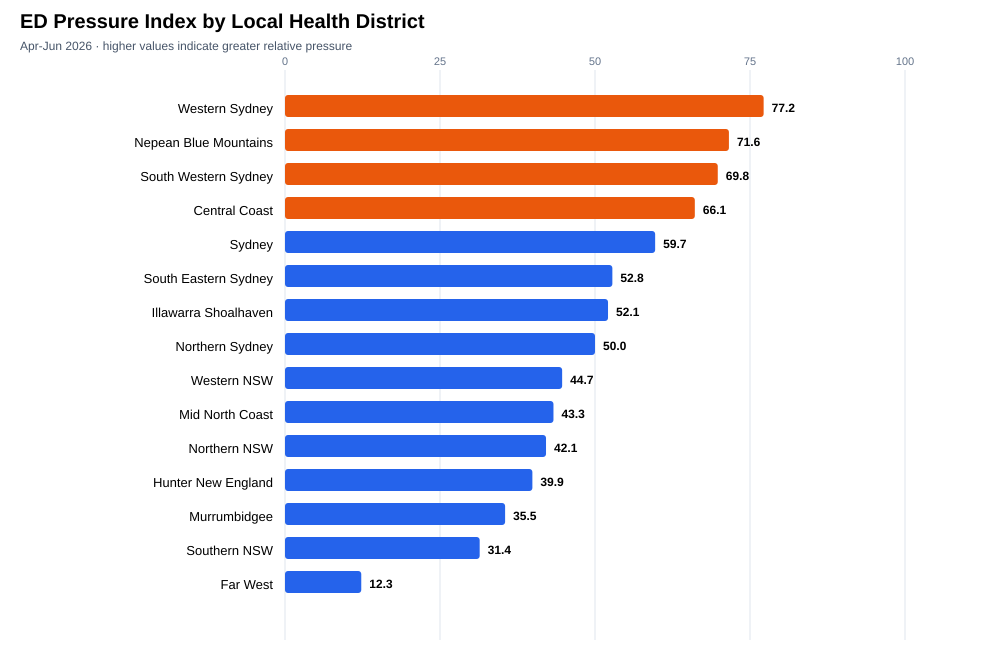

In [11]:
import csv
import math
from html import escape
from statistics import median, pstdev

from IPython.display import HTML, SVG, display

# Use BHI's published LHD aggregates; medians and percentiles cannot be summed from hospitals.
separation_files = sorted(
    bhi_data_directory.glob("*_ED_*__Results_by_separation.csv")
)
if len(separation_files) != 1:
    raise FileNotFoundError(
        f"Expected one ED separation-results file, found {len(separation_files)}."
    )

with separation_files[0].open(encoding="utf-8-sig", newline="") as csv_file:
    ed_separation_results = list(csv.DictReader(csv_file))

quarter_order = {"Jan": 1, "Apr": 2, "Jul": 3, "Oct": 4}

def period_key(period):
    return int(period[-4:]), quarter_order[period[:3]]

def is_local_health_district(row):
    return (
        row["reporting_level"] == "LHD"
        and row["entity_longname"].endswith("Local Health District")
    )

def values_by_lhd(rows, period, measure, category=None, subcategory=None):
    values = {}
    for row in rows:
        if not is_local_health_district(row):
            continue
        if row["reporting_period"] != period or row["measure_name"] != measure:
            continue
        if category is not None and row["reporting_category"] != category:
            continue
        if subcategory is not None and row["subcategory"] != subcategory:
            continue
        if row["measure_value"].strip():
            values[row["entity_shortname"]] = float(row["measure_value"])
    return values

def year_on_year_log_growth(current, previous):
    return {
        entity: math.log(current[entity] / previous[entity])
        for entity in current.keys() & previous.keys()
        if current[entity] > 0 and previous[entity] > 0
    }

def robust_z_scores(values):
    centre = median(values.values())
    mad = median(abs(value - centre) for value in values.values())
    scale = 1.4826 * mad
    if scale == 0:
        scale = pstdev(values.values()) or 1.0
    return {
        entity: max(-3.0, min(3.0, (value - centre) / scale))
        for entity, value in values.items()
    }

def combine_scores(score_maps, weights, entities):
    return {
        entity: sum(weight * scores[entity] for scores, weight in zip(score_maps, weights))
        for entity in entities
    }

latest_period = max(
    {
        row["reporting_period"]
        for row in ed_overall_results
        if is_local_health_district(row)
    },
    key=period_key,
)
previous_year_period = f"{latest_period[:-4]}{int(latest_period[-4:]) - 1}"

# Demand uses annual growth so larger districts are not automatically scored as pressured.
emergency_growth = year_on_year_log_growth(
    values_by_lhd(ed_overall_results, latest_period, "Emergency presentations"),
    values_by_lhd(ed_overall_results, previous_year_period, "Emergency presentations"),
)
ambulance_growth = year_on_year_log_growth(
    values_by_lhd(ed_overall_results, latest_period, "Arrivals by ambulance"),
    values_by_lhd(ed_overall_results, previous_year_period, "Arrivals by ambulance"),
)

median_ed_time = values_by_lhd(
    ed_separation_results, latest_period, "Median time spent in the ED",
    category="MOS", subcategory="All ED attendances",
)
p90_ed_time = values_by_lhd(
    ed_separation_results, latest_period, "90th percentile time spent in the ED",
    category="MOS", subcategory="All ED attendances",
)
within_12_hours = values_by_lhd(
    ed_separation_results, latest_period,
    "Percentage of patients leaving ED within specified time",
    category="Benchmark",
    subcategory="Spent 12 hours or less in ED (all attendances)",
)
treatment_on_time = values_by_lhd(
    ed_overall_results, latest_period,
    "Percentage of patients starting treatment on time",
)
median_handover = values_by_lhd(
    ed_overall_results, latest_period,
    "Median time to transfer care from paramedics to ED staff",
)
p90_handover = values_by_lhd(
    ed_overall_results, latest_period,
    "90th percentile time to transfer care from paramedics to ED staff",
)
handover_within_30 = values_by_lhd(
    ed_overall_results, latest_period,
    "Percentage of patients transferred from paramedics to ED staff within 30 minutes",
)

signal_values = [
    emergency_growth, ambulance_growth, median_ed_time, p90_ed_time, within_12_hours,
    treatment_on_time, median_handover, p90_handover, handover_within_30,
]
included_lhds = set.intersection(*(set(values) for values in signal_values))
if len(included_lhds) != 15:
    raise ValueError(f"Expected complete data for 15 LHDs, found {len(included_lhds)}.")

demand_score = combine_scores(
    [robust_z_scores(emergency_growth), robust_z_scores(ambulance_growth)],
    [0.60, 0.40], included_lhds,
)
flow_score = combine_scores(
    [
        robust_z_scores(median_ed_time),
        robust_z_scores(p90_ed_time),
        robust_z_scores({entity: -value for entity, value in within_12_hours.items()}),
    ],
    [2 / 7, 3 / 7, 2 / 7], included_lhds,
)
treatment_score = robust_z_scores(
    {entity: -value for entity, value in treatment_on_time.items()}
)
handover_score = combine_scores(
    [
        robust_z_scores(median_handover),
        robust_z_scores(p90_handover),
        robust_z_scores({entity: -value for entity, value in handover_within_30.items()}),
    ],
    [0.25, 0.50, 0.25], included_lhds,
)

composite_score = combine_scores(
    [demand_score, flow_score, treatment_score, handover_score],
    [0.25, 0.35, 0.20, 0.20], included_lhds,
)
composite_z = robust_z_scores(composite_score)
lhd_pressure_results = sorted(
    [
        {
            "lhd": entity,
            "pressure_index": round(max(0, min(100, 50 + 15 * composite_z[entity])), 1),
            "demand_z": demand_score[entity],
            "flow_z": flow_score[entity],
            "treatment_z": treatment_score[entity],
            "handover_z": handover_score[entity],
        }
        for entity in included_lhds
    ],
    key=lambda row: row["pressure_index"],
    reverse=True,
)

# Dependency-free horizontal SVG bar chart, ordered from highest to lowest pressure.
chart_width = 1000
bar_start = 285
bar_scale = 6.2
row_height = 34
chart_top = 108
chart_height = chart_top + row_height * len(lhd_pressure_results) + 50
svg_parts = [
    f"<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 {chart_width} {chart_height}' "
    "role='img' aria-labelledby='chart-title chart-description'>",
    f"<title id='chart-title'>LHD pressure index for {escape(latest_period)}</title>",
    "<desc id='chart-description'>Horizontal bars ordered from highest to lowest pressure.</desc>",
    "<style>text{font-family:Arial,sans-serif}.label{font-size:13px}.score{font-size:12px;font-weight:bold}"
    ".tick{font-size:11px;fill:#64748b}.title{font-size:20px;font-weight:bold}.subtitle{font-size:12px;fill:#475569}</style>",
    "<text id='chart-title-text' x='20' y='28' class='title'>ED Pressure Index by Local Health District</text>",
    f"<text x='20' y='50' class='subtitle'>{escape(latest_period)} · higher values indicate greater relative pressure</text>",
]
for tick in range(0, 101, 25):
    x = bar_start + tick * bar_scale
    svg_parts.append(
        f"<line x1='{x}' y1='70' x2='{x}' y2='{chart_height - 28}' stroke='#e2e8f0'/>"
        f"<text x='{x}' y='65' text-anchor='middle' class='tick'>{tick}</text>"
    )
for index, row in enumerate(lhd_pressure_results):
    y = chart_top + index * row_height
    score = row["pressure_index"]
    bar_width = score * bar_scale
    colour = "#b91c1c" if score >= 80 else "#ea580c" if score >= 65 else "#2563eb"
    svg_parts.extend([
        f"<text x='{bar_start - 12}' y='{y + 5}' text-anchor='end' class='label'>{escape(row['lhd'])}</text>",
        f"<rect x='{bar_start}' y='{y - 13}' width='{bar_width}' height='22' rx='3' fill='{colour}'/>",
        f"<text x='{bar_start + bar_width + 8}' y='{y + 4}' class='score'>{score:.1f}</text>",
    ])
svg_parts.append("</svg>")
display(SVG("".join(svg_parts)))
display(HTML(
    "<p><small>The index is a relative comparison for the latest quarter, not a clinical threshold. "
    "Demand uses year-on-year growth; other measures compare current performance across LHDs. "
    "St Vincent's Health Network and Sydney Children's Hospitals Network are excluded because "
    "they are specialist networks rather than Local Health Districts.</small></p>"
))

In [ ]:
western_sydney_results = [
    row
    for row in ed_overall_results
    if row["reporting_level"] == "LHD"
    and row["entity_shortname"] == "Western Sydney"
]

western_sydney_dataset_length = len(western_sydney_results)
print(f"Western Sydney dataset length: {western_sydney_dataset_length:,} rows")

## Western Sydney XGBoost forecasting pipeline

This pipeline forecasts the next quarter for the **seven ED measures that remain available from Jul–Sep 2013 through the latest published quarter**. The discontinued patient-flow measures are deliberately excluded.

The pipeline has five stages:

1. Filter the BHI data to Western Sydney LHD and the seven continuing measures.
2. Convert the long table into one quarterly time series per measure.
3. Create lagged, rolling and seasonal features using past information only.
4. Backtest one conservative XGBoost model per measure against a seasonal-naive baseline.
5. Forecast the next quarter and convert the pressure-related forecasts into a Western Sydney core Pressure Index.

> **Sample-size warning:** these are quarterly aggregate data, so the common training window contains only 52 observations. Shallow trees and walk-forward validation reduce overfitting risk, but the output is still an experimental forecast rather than an operational or clinical threshold.

In [13]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor

STABLE_MEASURES = [
    "Attendances",
    "Emergency presentations",
    "Percentage of patients starting treatment on time",
    "Arrivals by ambulance",
    "Percentage of patients transferred from paramedics to ED staff within 30 minutes",
    "Median time to transfer care from paramedics to ED staff",
    "90th percentile time to transfer care from paramedics to ED staff",
]

quarter_number = {"Jan": 1, "Apr": 2, "Jul": 3, "Oct": 4}
quarter_name = {1: "Jan-Mar", 2: "Apr-Jun", 3: "Jul-Sep", 4: "Oct-Dec"}

def parse_bhi_quarter(label):
    """Convert a label such as 'Apr-Jun 2026' into a sortable quarter."""
    return pd.Period(
        year=int(label[-4:]),
        quarter=quarter_number[label[:3]],
        freq="Q-DEC",
    )

def format_quarter(period):
    return f"{quarter_name[period.quarter]} {period.year}"

ed_overall_df = pd.read_csv(ed_overall_path, low_memory=False)
ed_overall_df["quarter"] = ed_overall_df["reporting_period"].map(parse_bhi_quarter)

western_sydney_long = ed_overall_df.loc[
    (ed_overall_df["reporting_level"] == "LHD")
    & (ed_overall_df["entity_shortname"] == "Western Sydney")
    & ed_overall_df["measure_name"].isin(STABLE_MEASURES),
    ["quarter", "measure_name", "metric", "measure_value"],
].copy()

western_sydney_wide = (
    western_sydney_long
    .pivot(index="quarter", columns="measure_name", values="measure_value")
    .sort_index()[STABLE_MEASURES]
    .dropna()
)

latest_observed_quarter = western_sydney_wide.index.max()
forecast_quarter = latest_observed_quarter + 1
metric_by_measure = (
    western_sydney_long.drop_duplicates("measure_name")
    .set_index("measure_name")["metric"]
    .to_dict()
)

coverage = pd.DataFrame({
    "Measure": STABLE_MEASURES,
    "Unit": [metric_by_measure[measure] for measure in STABLE_MEASURES],
    "First common quarter": format_quarter(western_sydney_wide.index.min()),
    "Latest quarter": format_quarter(latest_observed_quarter),
    "Observations": len(western_sydney_wide),
})

print(
    f"Training window: {format_quarter(western_sydney_wide.index.min())} to "
    f"{format_quarter(latest_observed_quarter)} ({len(western_sydney_wide)} quarters)"
)
print(f"Forecast quarter: {format_quarter(forecast_quarter)}")
display(coverage)

Training window: Jul-Sep 2013 to Apr-Jun 2026 (52 quarters)
Forecast quarter: Jul-Sep 2026


,Measure,Unit,First common quarter,Latest quarter,Observations
0,Attendances,Number,Jul-Sep 2013,Apr-Jun 2026,52
1,Emergency presentations,Number,Jul-Sep 2013,Apr-Jun 2026,52
2,Percentage of patients starting treatment on time,%,Jul-Sep 2013,Apr-Jun 2026,52
3,Arrivals by ambulance,Number,Jul-Sep 2013,Apr-Jun 2026,52
4,Percentage of patients transferred from parame...,%,Jul-Sep 2013,Apr-Jun 2026,52
5,Median time to transfer care from paramedics t...,Minutes,Jul-Sep 2013,Apr-Jun 2026,52
6,90th percentile time to transfer care from par...,Minutes,Jul-Sep 2013,Apr-Jun 2026,52


### Feature engineering without data leakage

Each model receives only values known before the quarter it predicts:

- `lag_1` and `lag_2`: the previous one and two quarters
- `lag_4`: the same quarter one year earlier
- `rolling_mean_4` and `rolling_std_4`: the level and variability of the previous year
- `quarter_sin` and `quarter_cos`: a cyclical representation of seasonality
- `trend`: the position of the observation in time

Calling `shift(1)` before calculating rolling features is important: it prevents the target quarter from leaking into its own predictors.

In [14]:
FEATURE_COLUMNS = [
    "lag_1", "lag_2", "lag_4",
    "rolling_mean_4", "rolling_std_4",
    "quarter_sin", "quarter_cos", "trend",
]

def build_supervised_data(series):
    """Turn one quarterly series into features and a target column."""
    series = series.astype(float).sort_index()
    features = pd.DataFrame(index=series.index)
    features["lag_1"] = series.shift(1)
    features["lag_2"] = series.shift(2)
    features["lag_4"] = series.shift(4)
    features["rolling_mean_4"] = series.shift(1).rolling(4).mean()
    features["rolling_std_4"] = series.shift(1).rolling(4).std(ddof=0)

    angle = 2 * np.pi * (series.index.quarter - 1) / 4
    features["quarter_sin"] = np.sin(angle)
    features["quarter_cos"] = np.cos(angle)
    features["trend"] = np.arange(len(series))
    return features.assign(target=series).dropna()

def build_next_quarter_features(series, next_quarter):
    """Build the single feature row required for the future forecast."""
    series = series.astype(float).sort_index()
    angle = 2 * math.pi * (next_quarter.quarter - 1) / 4
    return pd.DataFrame([{
        "lag_1": series.iloc[-1],
        "lag_2": series.iloc[-2],
        "lag_4": series.iloc[-4],
        "rolling_mean_4": series.iloc[-4:].mean(),
        "rolling_std_4": series.iloc[-4:].std(ddof=0),
        "quarter_sin": math.sin(angle),
        "quarter_cos": math.cos(angle),
        "trend": len(series),
    }], index=[next_quarter])

def make_xgboost_model():
    """A deliberately small model for a short quarterly time series."""
    return XGBRegressor(
        n_estimators=120,
        max_depth=2,
        learning_rate=0.035,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1,
        verbosity=0,
    )

### Walk-forward validation and the seasonal-naive benchmark

Random train/test splitting would let later quarters help predict earlier quarters. Instead, the final eight observed quarters are tested one at a time: each model is fitted only on quarters that precede the quarter being predicted.

The seasonal-naive forecast is primarily a **validation benchmark**, not a trained model. It estimates no parameters and simply uses the value from the same quarter one year earlier. Its purpose is to answer: **does XGBoost add predictive value beyond this zero-training seasonal rule?**

The notebook also uses that benchmark as a safety guardrail. If XGBoost has a higher backtest mean absolute error (MAE), the pipeline retains the seasonal-naive forecast. This is useful evidence, not a failure: sophisticated models do not automatically outperform simple rules on short time series.

In [15]:
BACKTEST_QUARTERS = 8
xgboost_models = {}
forecast_records = []

def valid_measure_value(value, unit):
    """Keep counts/times non-negative and percentages between 0 and 100."""
    if unit == "%":
        return float(np.clip(value, 0, 100))
    return float(max(0, value))

for measure in STABLE_MEASURES:
    series = western_sydney_wide[measure].astype(float)
    model_data = build_supervised_data(series)
    validation_start = len(model_data) - BACKTEST_QUARTERS

    actual_values = []
    xgboost_predictions = []
    seasonal_predictions = []

    # Expanding window: the training set grows by one quarter on each iteration.
    for position in range(validation_start, len(model_data)):
        training_fold = model_data.iloc[:position]
        validation_row = model_data.iloc[[position]]

        fold_model = make_xgboost_model()
        fold_model.fit(training_fold[FEATURE_COLUMNS], training_fold["target"])

        actual_values.append(float(validation_row["target"].iloc[0]))
        xgboost_predictions.append(
            float(fold_model.predict(validation_row[FEATURE_COLUMNS])[0])
        )
        seasonal_predictions.append(float(validation_row["lag_4"].iloc[0]))

    xgboost_mae = mean_absolute_error(actual_values, xgboost_predictions)
    seasonal_mae = mean_absolute_error(actual_values, seasonal_predictions)
    improvement = 100 * (1 - xgboost_mae / seasonal_mae) if seasonal_mae else np.nan

    # Refit on every available observation before forecasting the next quarter.
    final_model = make_xgboost_model()
    final_model.fit(model_data[FEATURE_COLUMNS], model_data["target"])
    next_features = build_next_quarter_features(series, forecast_quarter)
    unit = metric_by_measure[measure]
    xgboost_forecast = valid_measure_value(
        final_model.predict(next_features[FEATURE_COLUMNS])[0], unit
    )
    seasonal_forecast = valid_measure_value(series.iloc[-4], unit)

    xgboost_wins = xgboost_mae <= seasonal_mae
    selected_method = "XGBoost" if xgboost_wins else "Seasonal naive"
    selected_forecast = xgboost_forecast if xgboost_wins else seasonal_forecast
    xgboost_models[measure] = final_model

    forecast_records.append({
        "Measure": measure,
        "Unit": unit,
        "XGBoost forecast": xgboost_forecast,
        "Seasonal forecast": seasonal_forecast,
        "Recommended forecast": selected_forecast,
        "Selected method": selected_method,
        "XGBoost MAE": xgboost_mae,
        "Seasonal MAE": seasonal_mae,
        "XGBoost improvement (%)": improvement,
    })

forecast_results = pd.DataFrame(forecast_records)
xgboost_forecasts = forecast_results.set_index("Measure")["XGBoost forecast"].to_dict()
selected_forecasts = forecast_results.set_index("Measure")["Recommended forecast"].to_dict()

forecast_display = forecast_results.copy()
numeric_columns = forecast_display.select_dtypes(include="number").columns
forecast_display[numeric_columns] = forecast_display[numeric_columns].round(1)
print(f"Forecasts for Western Sydney LHD — {format_quarter(forecast_quarter)}")
display(forecast_display)

Forecasts for Western Sydney LHD — Jul-Sep 2026


,Measure,Unit,XGBoost forecast,Seasonal forecast,Recommended forecast,Selected method,XGBoost MAE,Seasonal MAE,XGBoost improvement (%)
0,Attendances,Number,55743.5,56484.0,56484.0,Seasonal naive,1118.9,1097.0,-2.0
1,Emergency presentations,Number,55087.8,55775.0,55775.0,Seasonal naive,1139.5,1089.1,-4.6
2,Percentage of patients starting treatment on time,%,53.9,48.4,53.9,XGBoost,3.2,4.0,20.4
3,Arrivals by ambulance,Number,16182.6,16464.0,16464.0,Seasonal naive,253.3,177.5,-42.7
4,Percentage of patients transferred from parame...,%,70.6,66.2,70.6,XGBoost,3.9,7.6,48.8
5,Median time to transfer care from paramedics t...,Minutes,17.4,19.0,17.4,XGBoost,1.3,1.4,6.3
6,90th percentile time to transfer care from par...,Minutes,72.8,89.0,72.8,XGBoost,14.6,21.9,33.3


### Core ED Pressure Index

The discontinued patient-flow domain is not used. The stable core index is therefore reweighted across three domains:

| Domain | Forecast signals | Index weight |
|---|---|---:|
| Demand | Year-over-year growth in emergency presentations and ambulance arrivals | 40% |
| Treatment timeliness | Inverse of patients starting treatment on time | 25% |
| Ambulance handover | Median and 90th-percentile transfer time, plus the inverse of transfer within 30 minutes | 35% |

`Attendances` is forecast but excluded from the index because it overlaps strongly with `Emergency presentations`. Each signal is converted to a robust z-score against Western Sydney's most recent 20-quarter history. Higher values always mean more pressure. The final conversion is `50 + 15 × composite z-score`, capped to 0–100.

,Scenario,Pressure Index,Interpretation
0,Validated pipeline (recommended),47.0,Within usual range
1,XGBoost forecasts only,44.9,Within usual range


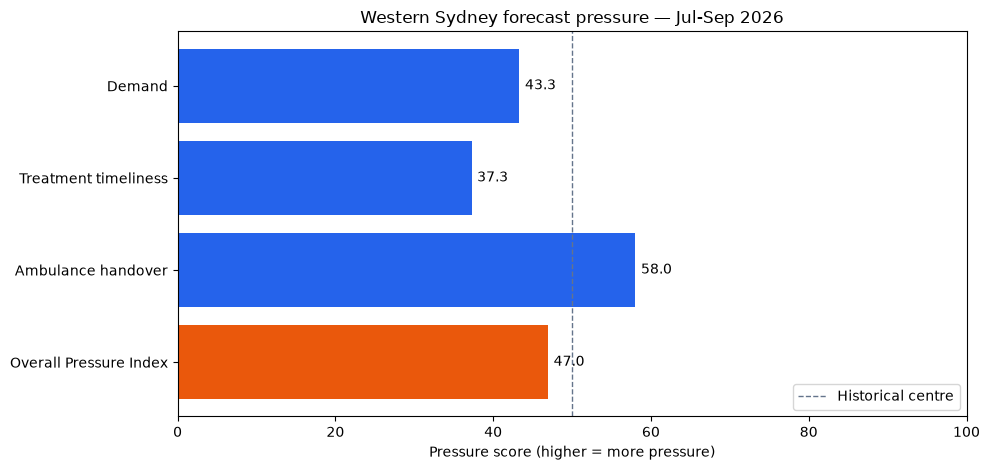

Recommended forecast Pressure Index: 47.0 (Within usual range)


In [16]:
EMERGENCY = "Emergency presentations"
AMBULANCE = "Arrivals by ambulance"
TREATMENT = "Percentage of patients starting treatment on time"
HANDOVER_MEDIAN = "Median time to transfer care from paramedics to ED staff"
HANDOVER_P90 = "90th percentile time to transfer care from paramedics to ED staff"
HANDOVER_30 = "Percentage of patients transferred from paramedics to ED staff within 30 minutes"

def robust_pressure_z(value, history, direction=1):
    """Express a forecast relative to recent history; positive always means pressure."""
    reference = pd.Series(history).dropna().astype(float).tail(20)
    centre = reference.median()
    mad = (reference - centre).abs().median()
    scale = 1.4826 * mad
    if scale == 0:
        scale = reference.std(ddof=0) or 1.0
    return float(np.clip(direction * (value - centre) / scale, -3, 3))

def calculate_pressure_index(forecasts):
    """Calculate Western Sydney's self-relative core pressure score."""
    prior_year_quarter = forecast_quarter - 4

    emergency_growth = math.log(
        forecasts[EMERGENCY] / western_sydney_wide.loc[prior_year_quarter, EMERGENCY]
    )
    ambulance_growth = math.log(
        forecasts[AMBULANCE] / western_sydney_wide.loc[prior_year_quarter, AMBULANCE]
    )
    historical_emergency_growth = np.log(
        western_sydney_wide[EMERGENCY] / western_sydney_wide[EMERGENCY].shift(4)
    )
    historical_ambulance_growth = np.log(
        western_sydney_wide[AMBULANCE] / western_sydney_wide[AMBULANCE].shift(4)
    )

    demand_z = (
        0.625 * robust_pressure_z(emergency_growth, historical_emergency_growth)
        + 0.375 * robust_pressure_z(ambulance_growth, historical_ambulance_growth)
    )
    treatment_z = robust_pressure_z(
        forecasts[TREATMENT], western_sydney_wide[TREATMENT], direction=-1
    )
    handover_z = (
        0.25 * robust_pressure_z(
            forecasts[HANDOVER_MEDIAN], western_sydney_wide[HANDOVER_MEDIAN]
        )
        + 0.50 * robust_pressure_z(
            forecasts[HANDOVER_P90], western_sydney_wide[HANDOVER_P90]
        )
        + 0.25 * robust_pressure_z(
            forecasts[HANDOVER_30], western_sydney_wide[HANDOVER_30], direction=-1
        )
    )

    composite_z = 0.40 * demand_z + 0.25 * treatment_z + 0.35 * handover_z
    pressure_index = float(np.clip(50 + 15 * composite_z, 0, 100))
    return {
        "Demand": demand_z,
        "Treatment timeliness": treatment_z,
        "Ambulance handover": handover_z,
        "Composite": composite_z,
        "Pressure Index": pressure_index,
    }

validated_pressure = calculate_pressure_index(selected_forecasts)
xgboost_only_pressure = calculate_pressure_index(xgboost_forecasts)
forecast_pressure_index = validated_pressure["Pressure Index"]

def pressure_band(score):
    if score < 35:
        return "Below usual"
    if score < 65:
        return "Within usual range"
    if score < 80:
        return "Elevated"
    return "Very elevated"

pressure_comparison = pd.DataFrame([
    {
        "Scenario": "Validated pipeline (recommended)",
        "Pressure Index": validated_pressure["Pressure Index"],
        "Interpretation": pressure_band(validated_pressure["Pressure Index"]),
    },
    {
        "Scenario": "XGBoost forecasts only",
        "Pressure Index": xgboost_only_pressure["Pressure Index"],
        "Interpretation": pressure_band(xgboost_only_pressure["Pressure Index"]),
    },
])
pressure_comparison["Pressure Index"] = pressure_comparison["Pressure Index"].round(1)
display(pressure_comparison)

domain_scores = {
    domain: float(np.clip(50 + 15 * validated_pressure[domain], 0, 100))
    for domain in ["Demand", "Treatment timeliness", "Ambulance handover"]
}
domain_scores["Overall Pressure Index"] = forecast_pressure_index

fig, ax = plt.subplots(figsize=(10, 4.8))
labels = list(domain_scores)
scores = list(domain_scores.values())
colours = ["#2563eb", "#2563eb", "#2563eb", "#ea580c"]
bars = ax.barh(labels, scores, color=colours)
ax.axvline(50, color="#64748b", linestyle="--", linewidth=1, label="Historical centre")
ax.set_xlim(0, 100)
ax.set_xlabel("Pressure score (higher = more pressure)")
ax.set_title(f"Western Sydney forecast pressure — {format_quarter(forecast_quarter)}")
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{score:.1f}" for score in scores], padding=4)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(
    f"Recommended forecast Pressure Index: {forecast_pressure_index:.1f} "
    f"({pressure_band(forecast_pressure_index)})"
)

### How to interpret the result

- The **XGBoost forecast** column shows what each fitted model predicts.
- The **recommended forecast** uses XGBoost only when it beats the seasonal-naive method in the eight-quarter walk-forward backtest.
- The Pressure Index is relative to Western Sydney's own recent history. It should not be compared directly with the earlier cross-sectional LHD index, which used a different peer-relative calibration.
- The bands are descriptive labels, not validated clinical escalation thresholds.
- Additional predictors such as staffing, staffed treatment spaces, inpatient occupancy, weather and respiratory activity would be needed before operational deployment.